# 2. Daily oblast frost-kill signals, 2000/01 to 2025/26

This notebook runs FROSTOL in every wheat cell of Rostov, Krasnodar, Stavropol and Odessa for 26 winters, with the same model set-up as `01_signal_generation.ipynb`. It aggregates the daily cumulative kill `RF_FROST_T` into one series per oblast and two basin series. The paper uses the Rostov series, `output/oblast_signal/frostol_oblast_rostov_daily.csv`, as the frost-kill signal in `03_local_projection.ipynb`. The other series support robustness checks.

## Aggregation

Kill is computed per cell and weighted by CROPGRIDS wheat **area** (harvested hectares, not production). On each day the weights are renormalised over the cells that report, and the reporting share is exported as `wheat_coverage`. Without the renormalisation a missing cell would pull the oblast mean down in proportion to its weight.

Weighting cells to oblasts and oblasts to the basin by area is identical to weighting every cell by its share of basin area in one step, and section 7 checks this numerically. Equal-weighting the oblasts would not be neutral, because it over-weights the smallest producer.

## Assumptions

| # | Assumption | Risk |
|---|---|---|
| A1 | Weather is not averaged. FROSTOL runs per cell and only outputs are pooled. | Low. Averaging weather first smooths the cold tail that drives kill. |
| A2 | Kill aggregates linearly in area. | Moderate. Correct for area lost, not for production lost, since yield varies. |
| A3 | Weights are static (one CROPGRIDS vintage). | Low. Time-varying weights would add non-frost variation. |
| A4 | `LT50C = −18 °C` in all four oblasts. | See the provenance table below. |
| A5 | `SNOWDENSITY = 0.164`, calibrated in Tula. | High. MOCCCASIN D5.3 (Table 3) fits range from 0.022 to 0.427 across stations, and southern snow is thinner and more transient. Sensitivity is near-linear (D5.3, 7.2.4), so it biases the level more than the timing. |
| A6 | `CROWNTMPB = 0.5`. | High. D5.3 (7.2.5) places it on the steep part of the response curve. |
| A7 | Sowing on 1 October and harvest on 15 May in every cell and year. | Moderate. Real sowing varies and is later in the north. D5.3 (7.2.1) finds a near-linear impact except after 15 October. |
| A8 | Cells with a failed or short season are excluded, not imputed. | Low. Coverage is reported per day. |
| A9 | Odessa carries a war confound from 2022. | High for the price analysis, not for the biophysics. The `RU3` basin variant excludes Odessa. |

## LT50C provenance by oblast

Cultivar support from the Fedoulov (1998) reconstruction:

| Oblast | Fedoulov cultivars | Status |
|---|---|---|
| Rostov | 4 (Don group) | Native. `−18 °C` is derived from these cultivars. |
| Krasnodar | 9 | Derived value `−17.8 °C`, 0.88 °C from Don against 3.0 °C of test-temperature uncertainty. Not distinguishable from −18. |
| Odessa | 2 | Both near −18 (−18.61 and −18.47). Thin but consistent. |
| Stavropol | 0 | No cultivar support. A short interpolation between two covered regions. |

Because the 3.0 °C test-temperature uncertainty exceeds the 0.88 °C regional spread, the baseline uses a single `−18 °C`. The per-oblast values in `OBLASTS` are for a sensitivity run only (`USE_PER_OBLAST_LT50C = True`).

## Runtime

FROSTOL output is cached per cell in `output/oblast_signal/cell_cache/`, keyed on snow scheme and `LT50C`. With the cache present the notebook runs in seconds. Without it, the first pass makes one NASA POWER request per cell and simulates 26 winters per cell. Delete the cache to force a full rerun.

Run from the repository root.

In [1]:
# ============================================================================
# 1. IMPORTS
# ============================================================================
import sys, os, time, copy, json, datetime as dt
from pathlib import Path
import numpy as np, pandas as pd, yaml
import matplotlib.pyplot as plt

ROOT   = Path.cwd()                    # run from the repository root
DATA   = ROOT / "data"
OUT    = ROOT / "output"
FIGDIR = OUT / "figures"
FIGDIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "functions"))

import pcse
import fix_winterkill          # patches PCSE 6.0.12; import once, before any Engine
import power_snow as ps        # POWER snow depth, used by the prescribed-snow option

from pcse.engine import Engine
from pcse.base import ParameterProvider
from pcse.input import (YAMLCropDataProvider, CABOFileReader,
                        WOFOST72SiteDataProvider, NASAPowerWeatherDataProvider)

print("pcse:", pcse.__version__, "| pandas:", pd.__version__)

[fix_winterkill] patch applied (PGASS/PMRES locals + REALLOC published)
[fix_winterkill] _on_CROP_FINISH signature aligned
[fix_winterkill] NASA POWER end-date capped to today-30d
[fix_winterkill] RAIN range loosened to (0, 100) cm/day for NASA POWER outliers
pcse: 6.0.12 | pandas: 3.0.1


In [2]:
# ============================================================================
# 2. CONFIG
# ============================================================================
SNOW_SCHEME  = "snowmaus"     # "snowmaus" (ISNOWSRC=1) | "prescribed" (ISNOWSRC=0)
POWER_USER   = "wurblacksea"
SEASON_END   = "05-15"
SOW_MMDD     = "10-01"
LP_SEASONS   = range(2000, 2026)
FETCH_CSV    = DATA / "fetch_points_0.5deg_labeled.csv"

WEIGHT_MODE  = "area"         # "area" = CROPGRIDS wheat_ha (default)
                              # "production" = wheat_ha * OBLAST_YIELD (needs real yields)

# Minimum share of oblast wheat area that must report on a day for that day to be
# marked reliable. Days below this are kept but flagged in `coverage_ok`.
MIN_COVERAGE = 0.80

# --- the four oblasts -------------------------------------------------------
# lt50c: per-oblast values for a sensitivity run only. The baseline uses -18.0 everywhere.
# bbox : (lat_min, lat_max, lon_min, lon_max) fallback only if the label join misses.
OBLASTS = {
    "Rostov":    dict(patterns=["rostov"],                bbox=(46.0, 50.2, 38.2, 44.3),
                      lt50c=-18.0, provenance="native (Don, n=4)"),
    "Krasnodar": dict(patterns=["krasnodar"],             bbox=(43.4, 46.8, 37.3, 41.9),
                      lt50c=-17.8, provenance="indistinguishable from Don (n=9)"),
    "Stavropol": dict(patterns=["stavropol"],             bbox=(43.8, 46.3, 40.7, 45.5),
                      lt50c=-18.0, provenance="NO cultivar support (n=0)"),
    "Odessa":    dict(patterns=["odessa","odesa","odes"], bbox=(45.2, 48.3, 28.3, 31.4),
                      lt50c=-18.5, provenance="consistent, thin (n=2)"),
}

# Basin variants written out. RU3 excludes the Ukrainian war confound.
BASIN_VARIANTS = {
    "BASIN4": ["Rostov", "Krasnodar", "Stavropol", "Odessa"],
    "RU3":    ["Rostov", "Krasnodar", "Stavropol"],
}

USE_PER_OBLAST_LT50C = False   # True only for the sensitivity run
OUTDIR = OUT / "oblast_signal"; OUTDIR.mkdir(parents=True, exist_ok=True)
CACHE  = OUTDIR / "cell_cache"; CACHE.mkdir(exist_ok=True)

print(f"snow={SNOW_SCHEME} | weights={WEIGHT_MODE} | per-oblast LT50C={USE_PER_OBLAST_LT50C}")
print(f"oblasts: {list(OBLASTS)}")
print(f"outputs -> {OUTDIR.relative_to(ROOT)}")

snow=snowmaus | weights=area | per-oblast LT50C=False
oblasts: ['Rostov', 'Krasnodar', 'Stavropol', 'Odessa']
outputs -> output/oblast_signal


In [3]:
# ============================================================================
# 3. FIXED MODEL INPUTS
# ============================================================================
crop = YAMLCropDataProvider(); crop.set_active_crop("wheat", "Winter_wheat_101")
soildata = CABOFileReader(DATA / "generic_medium.soil")
sitedata = WOFOST72SiteDataProvider(WAV=15)

BASE_FROST = {
    "FROSTOL_H": 0.0093, "FROSTOL_D": 2.7e-05, "FROSTOL_S": 1.910, "FROSTOL_R": 0.541,
    "FROSTOL_KILLCF": 1.0189,          # Russia calibration (vs 1.189 Scandinavian)
    "FROSTOL_SDBASE": 0.0, "FROSTOL_SDMAX": 12.5,
    "LT50C": -18.0, "LT50I": -4.01,
    "CROWNTMPA": 0.2, "CROWNTMPB": 0.5,  # A6: steep sensitivity, D5.3 sec.7.2.5
    "ISNOWSRC": 1 if SNOW_SCHEME == "snowmaus" else 0,
}
if SNOW_SCHEME == "snowmaus":
    BASE_FROST.update({
        "TMINACCU1": 0.0, "TMINACCU2": -6.0, "TMINCRIT": -12.0, "TMAXCRIT": 5.0,
        "RMELT": 0.042, "SCTHRESHOLD": 2.0,
        "SNOWDENSITY": 0.164,            # A5: Tula-calibrated
        "SWEDEPTHI": 0.0,
    })

def make_params(lt50c=None):
    p = ParameterProvider(cropdata=crop, soildata=soildata, sitedata=sitedata)
    ov = dict(BASE_FROST)
    if lt50c is not None:
        ov["LT50C"] = float(lt50c)
    for k, v in ov.items():
        p.set_override(k, v, check=False)
    return p

print("LT50C baseline:", BASE_FROST["LT50C"], "| ISNOWSRC:", BASE_FROST["ISNOWSRC"])

LT50C baseline: -18.0 | ISNOWSRC: 1


In [4]:
# ============================================================================
# 4. CELL SELECTION  (label join, bbox fallback, full diagnostics)
# ============================================================================
pts = pd.read_csv(FETCH_CSV)
print("fetch CSV columns:", list(pts.columns), "\nrows:", len(pts))

def _norm(s):
    return "".join(ch for ch in str(s).lower() if ch.isalnum())

def _col(df, *cands):
    for c in cands:
        if c in df.columns: return c
    for c in df.columns:
        if any(c.lower().startswith(x) for x in cands): return c
    raise KeyError(f"none of {cands} in {list(df.columns)}")

LATC = _col(pts, "lat"); LONC = _col(pts, "lon")
WCOL = "wheat_ha" if "wheat_ha" in pts.columns else next(c for c in pts.columns if "wheat" in c.lower())
PIDC = "pid" if "pid" in pts.columns else None

if "status" in pts.columns:
    n0 = len(pts); pts = pts[pts["status"] == "simulated"].copy()
    print(f"status filter: {n0} -> {len(pts)} cells")

sel, diag = [], []
for ob, cfg in OBLASTS.items():
    m = pd.Series(False, index=pts.index)
    how = "label"
    if "oblast" in pts.columns:
        nm = pts["oblast"].map(_norm)
        for p in cfg["patterns"]:
            m |= nm.str.contains(p, na=False)
    if m.sum() == 0:
        how = "BBOX FALLBACK"
        la, lb, lo, hi = cfg["bbox"]
        m = pts[LATC].between(la, lb) & pts[LONC].between(lo, hi)
    g = pts[m].copy(); g["oblast_name"] = ob
    g["pid"] = g[PIDC] if PIDC else (g[LATC].round(2).astype(str) + "_" + g[LONC].round(2).astype(str))
    sel.append(g)
    diag.append(dict(oblast=ob, how=how, n_cells=len(g),
                     wheat_kha=g[WCOL].sum()/1e3, provenance=cfg["provenance"]))

cellmeta = pd.concat(sel, ignore_index=True)
dup = cellmeta.pid.duplicated().sum()
diag = pd.DataFrame(diag)
diag["area_share"] = diag.wheat_kha / diag.wheat_kha.sum()

print("\n" + diag.round(3).to_string(index=False))
print(f"\ntotal cells {len(cellmeta)} | total wheat {cellmeta[WCOL].sum()/1e3:.0f} kha")
if dup: print(f"WARNING: {dup} duplicate pid across oblasts (overlapping bboxes?)")
if (diag.how == "BBOX FALLBACK").any():
    print("WARNING: bbox fallback used. Bboxes are rectangles and WILL grab")
    print("         neighbouring-oblast cells. Fix the admin-1 join before trusting these.")
assert len(cellmeta) > 0, "no cells selected"
cellmeta.to_csv(OUTDIR / "cells_selected.csv", index=False)

fetch CSV columns: ['pid', 'lon', 'lat', 'wheat_ha', 'country', 'oblast', 'note'] 
rows: 829

   oblast   how  n_cells  wheat_kha                       provenance  area_share
   Rostov label       46   1938.351                native (Don, n=4)       0.354
Krasnodar label       33   1345.894 indistinguishable from Don (n=9)       0.246
Stavropol label       28   1723.507        NO cultivar support (n=0)       0.314
   Odessa label       15    473.083           consistent, thin (n=2)       0.086

total cells 122 | total wheat 5481 kha


In [5]:
# ============================================================================
# 5. FROSTOL PER CELL  (checkpointed, so a crash does not lose the run)
# ============================================================================
_END_MM, _END_DD = map(int, SEASON_END.split("-"))
_SOW_MM, _SOW_DD = map(int, SOW_MMDD.split("-"))
MAX_FILL = 5
_snow_note = False
FILL_LOG = []

def get_power_wdp(lat, lon):
    global _snow_note
    wdp = NASAPowerWeatherDataProvider(latitude=lat, longitude=lon)
    depth = ps.fetch_power_snow(lat, lon, user=POWER_USER, verbose=(not _snow_note))
    _snow_note = True
    ps.attach_snow(wdp, depth)
    return wdp

def agro_for_season(y0, end_date):
    return yaml.safe_load(f'''
Version: 1.0
AgroManagement:
- {y0}-{_SOW_MM:02d}-{_SOW_DD:02d}:
    CropCalendar:
        crop_name: wheat
        variety_name: Winter_wheat_101
        crop_start_date: {y0}-{_SOW_MM:02d}-{_SOW_DD:02d}
        crop_start_type: sowing
        crop_end_date: {end_date}
        crop_end_type: harvest
        max_duration: 330
    TimedEvents: null
    StateEvents: null
''')["AgroManagement"]

def _prepare_season(wdp, sow, hard_end):
    present = {k[0] for k in wdp.store}
    if sow not in present: return None, 0
    d, filled = sow, 0
    while d < hard_end:
        nxt = d + dt.timedelta(days=1)
        if nxt in present: d = nxt; continue
        j = nxt
        while j <= hard_end and j not in present: j += dt.timedelta(days=1)
        if j > hard_end or (j - nxt).days > MAX_FILL: break
        base = wdp(d); g = nxt
        while g < j:
            wdc = copy.deepcopy(base); wdc.DAY = g
            wdp._store_WeatherDataContainer(wdc, g); present.add(g); filled += 1
            g += dt.timedelta(days=1)
        d = j - dt.timedelta(days=1)
    return d, filled

def daily_kill_cell_season(wdp, y0, lt50c, pid=None):
    sow = dt.date(y0, _SOW_MM, _SOW_DD)
    hard_end = min(dt.date(y0 + 1, _END_MM, _END_DD), wdp.last_date)
    end, filled = _prepare_season(wdp, sow, hard_end)      # keep `filled`
    FILL_LOG.append(dict(pid=pid, y0=y0, filled=filled, end=end,
                         hard_end=hard_end,
                         truncated=(end is not None and end < hard_end)))
    if end is None or (end - sow).days < 90:
        return None
    wf = Engine(make_params(lt50c), wdp, agro_for_season(y0, end.strftime("%Y-%m-%d")),
                config="Wofost_winterkill.conf")
    wf.run_till_terminate()
    out = pd.DataFrame(wf.get_output()).set_index("day")
    out.index = pd.to_datetime(out.index)
    return out["RF_FROST_T"].astype(float)

def run_cell(pid, lat, lon, lt50c):
    '''Return a tidy frame [date, season, RF_FROST_T] for one cell, cached to disk.'''
    tag = f"{pid}_{SNOW_SCHEME}_{lt50c:+.1f}".replace("/", "-")
    f = CACHE / f"{tag}.csv"
    if f.exists():
        d = pd.read_csv(f, parse_dates=["date"])
        return d, "cached"
    wdp = get_power_wdp(lat, lon)
    rows = []
    for y0 in LP_SEASONS:
        s = daily_kill_cell_season(wdp, y0, lt50c, pid=pid)
        if s is None: continue
        rows.append(pd.DataFrame({"date": s.index, "season": f"{y0}/{str(y0+1)[2:]}",
                                  "RF_FROST_T": s.values}))
    if not rows: return None, "no seasons"
    d = pd.concat(rows, ignore_index=True)
    d.to_csv(f, index=False)
    return d, "run"


print("helpers ready. cache ->", CACHE.relative_to(ROOT))

helpers ready. cache -> output/oblast_signal/cell_cache


In [6]:
# ============================================================================
# 6. RUN ALL CELLS
# ============================================================================
t0 = time.time()
frames, status = [], []

for n, r in enumerate(cellmeta.itertuples(), 1):
    ob = r.oblast_name
    lt = OBLASTS[ob]["lt50c"] if USE_PER_OBLAST_LT50C else BASE_FROST["LT50C"]
    try:
        d, how = run_cell(r.pid, getattr(r, LATC), getattr(r, LONC), lt)
    except Exception as e:
        status.append(dict(pid=r.pid, oblast=ob, status=f"FAIL: {str(e)[:70]}", n_seasons=0))
        print(f"  [{n}/{len(cellmeta)}] {r.pid} FAILED: {str(e)[:70]}")
        continue
    if d is None:
        status.append(dict(pid=r.pid, oblast=ob, status="no seasons", n_seasons=0)); continue
    d["pid"] = r.pid; d["oblast"] = ob
    d["wheat_ha"] = getattr(r, WCOL)
    frames.append(d)
    status.append(dict(pid=r.pid, oblast=ob, status=how, n_seasons=d.season.nunique()))
    if n % 5 == 0:
        print(f"  [{n}/{len(cellmeta)}] {(time.time()-t0)/60:.1f} min")

tidy = pd.concat(frames, ignore_index=True)
status = pd.DataFrame(status)
print(f"\ndone in {(time.time()-t0)/60:.1f} min | {tidy.pid.nunique()} cells | {len(tidy):,} cell-days")
print("\nstatus by oblast:")
print(status.groupby(["oblast","status"]).size().to_string())

# --- monotonicity check: RF_FROST_T must be non-decreasing within a season ---
neg = (tidy.sort_values("date").groupby(["pid","season"])["RF_FROST_T"]
          .diff().lt(-1e-9).sum())
print(f"\nnegative within-season increments: {neg}")
if neg: print("  WARNING: RF_FROST_T is not monotone. Investigate before clipping it away.")

# --- unbalanced-panel check --------------------------------------------------
sp = status[status.n_seasons > 0].n_seasons
print(f"seasons per cell: min {sp.min()} max {sp.max()} median {sp.median():.0f}")
if sp.min() != sp.max():
    print("  NOTE: unbalanced panel, handled by the daily weight renormalisation in section 7")
status.to_csv(OUTDIR / "cell_status.csv", index=False)

  [5/122] 0.0 min
  [10/122] 0.0 min
  [15/122] 0.0 min
  [20/122] 0.0 min
  [25/122] 0.0 min
  [30/122] 0.0 min
  [35/122] 0.0 min
  [40/122] 0.0 min
  [45/122] 0.0 min
  [50/122] 0.0 min
  [55/122] 0.0 min
  [60/122] 0.0 min
  [65/122] 0.0 min


  [70/122] 0.0 min


  [75/122] 0.0 min


  [80/122] 0.0 min


  [85/122] 0.0 min


  [90/122] 0.0 min
  [95/122] 0.0 min
  [100/122] 0.0 min
  [105/122] 0.0 min
  [110/122] 0.0 min
  [115/122] 0.0 min
  [120/122] 0.0 min

done in 0.0 min | 122 cells | 720,776 cell-days

status by oblast:
oblast     status
Krasnodar  cached    33
Odessa     cached    15
Rostov     cached    46
Stavropol  cached    28



negative within-season increments: 0
seasons per cell: min 26 max 26 median 26


In [7]:
# ============================================================================
# 7. AGGREGATION  cell -> oblast -> basin
# ============================================================================
def weight_of(df):
    if WEIGHT_MODE == "area":
        return df.wheat_ha
    raise NotImplementedError("production weighting needs oblast yields; see A2")

K = tidy.pivot_table(index="date", columns="pid", values="RF_FROST_T")
cw = tidy.groupby("pid").apply(lambda g: weight_of(g).iloc[0], include_groups=False)
cw = cw.reindex(K.columns).astype(float)
pid2ob = tidy.drop_duplicates("pid").set_index("pid")["oblast"].reindex(K.columns)

def aggregate(cols):
    '''Area-weighted mean over cols, renormalising each day over reporting cells.
    Returns (signal, coverage) where coverage = weight share actually reporting.'''
    sub, w = K[cols], cw[cols]
    present = sub.notna()
    wd = present.mul(w, axis=1)
    tot = wd.sum(axis=1)
    cov = tot / w.sum()
    wd = wd.div(tot.replace(0, np.nan), axis=0)
    sig = (sub.fillna(0.0) * wd).sum(axis=1).where(tot > 0)
    return sig, cov

# ---- per-oblast --------------------------------------------------------------
ob_sig, ob_cov, ob_w = {}, {}, {}
for ob in OBLASTS:
    cols = [c for c in K.columns if pid2ob[c] == ob]
    if not cols:
        print(f"  {ob}: NO CELLS, skipped"); continue
    ob_sig[ob], ob_cov[ob] = aggregate(cols)
    ob_w[ob] = float(cw[cols].sum())
ob_sig = pd.DataFrame(ob_sig); ob_cov = pd.DataFrame(ob_cov)
ob_w = pd.Series(ob_w)
print("oblast wheat area (kha):"); print((ob_w/1e3).round(0).to_string())

# ---- basin variants ----------------------------------------------------------
def season_of(d):
    return f"{d.year-1}/{str(d.year)[2:]}" if d.month < 8 else f"{d.year}/{str(d.year+1)[2:]}"

def finalise(sig, cov, name):
    o = sig.to_frame("RF_FROST_T")
    o["wheat_coverage"] = cov
    o["coverage_ok"] = cov >= MIN_COVERAGE
    o["season"] = o.index.map(season_of)
    g = o.groupby("season")["RF_FROST_T"]
    o["kill_incr"] = g.diff()
    first = o.groupby("season").head(1).index
    o.loc[first, "kill_incr"] = o.loc[first, "RF_FROST_T"]
    o["kill_incr"] = o["kill_incr"].clip(lower=0).fillna(0.0)
    o.index.name = "date"
    o = o[["RF_FROST_T","kill_incr","season","wheat_coverage","coverage_ok"]]
    o.to_csv(OUTDIR / f"frostol_{name}_daily.csv")
    return o

basins = {}
for name, obs in BASIN_VARIANTS.items():
    cols = [c for c in K.columns if pid2ob[c] in obs]
    s, c = aggregate(cols)
    basins[name] = finalise(s, c, name.lower())
    print(f"{name:7s} {len(basins[name]):5d} rows | {basins[name].index.min().date()} -> "
          f"{basins[name].index.max().date()} | mean coverage {c.mean():.3f} | "
          f"days below {MIN_COVERAGE:.0%}: {(c < MIN_COVERAGE).sum()}")

obl = {ob: finalise(ob_sig[ob], ob_cov[ob], f"oblast_{ob.lower()}") for ob in ob_sig.columns}

# ---- PROOF: two-stage == one-stage -------------------------------------------
obs4 = [o for o in BASIN_VARIANTS["BASIN4"] if o in ob_sig.columns]
W = ob_w[obs4] / ob_w[obs4].sum()
two = (ob_sig[obs4] * W).sum(axis=1)
one = basins["BASIN4"]["RF_FROST_T"]
d = (two - one).abs()
print(f"\ntwo-stage vs one-stage, max abs diff = {d.max():.3e}")
print("(they agree only on fully-covered days; gaps make the two-stage path differ)")
naive = ob_sig[obs4].mean(axis=1)
print(f"equal-weighting the oblasts instead would shift the signal by up to "
      f"{(naive - one).abs().max():.4f} kill fraction")

oblast wheat area (kha):
Rostov       1938.0
Krasnodar    1346.0
Stavropol    1724.0
Odessa        473.0


BASIN4   5908 rows | 2000-10-01 -> 2026-05-15 | mean coverage 1.000 | days below 80%: 0
RU3      5908 rows | 2000-10-01 -> 2026-05-15 | mean coverage 1.000 | days below 80%: 0

two-stage vs one-stage, max abs diff = 6.661e-16
(they agree only on fully-covered days; gaps make the two-stage path differ)
equal-weighting the oblasts instead would shift the signal by up to 0.0549 kill fraction


Rostov season totals, ranked (the paper signal):
         RF_FROST_T  kill_days  min_coverage  frac_days_ok
season                                                    
2019/20       0.442         11           1.0           1.0
2006/07       0.386          9           1.0           1.0
2014/15       0.344          6           1.0           1.0
2015/16       0.325         18           1.0           1.0
2009/10       0.317          4           1.0           1.0
2005/06       0.277         10           1.0           1.0
2008/09       0.213         11           1.0           1.0
2025/26       0.186         25           1.0           1.0
2013/14       0.171          4           1.0           1.0
2024/25       0.166          8           1.0           1.0
2010/11       0.143         16           1.0           1.0
2002/03       0.135          6           1.0           1.0


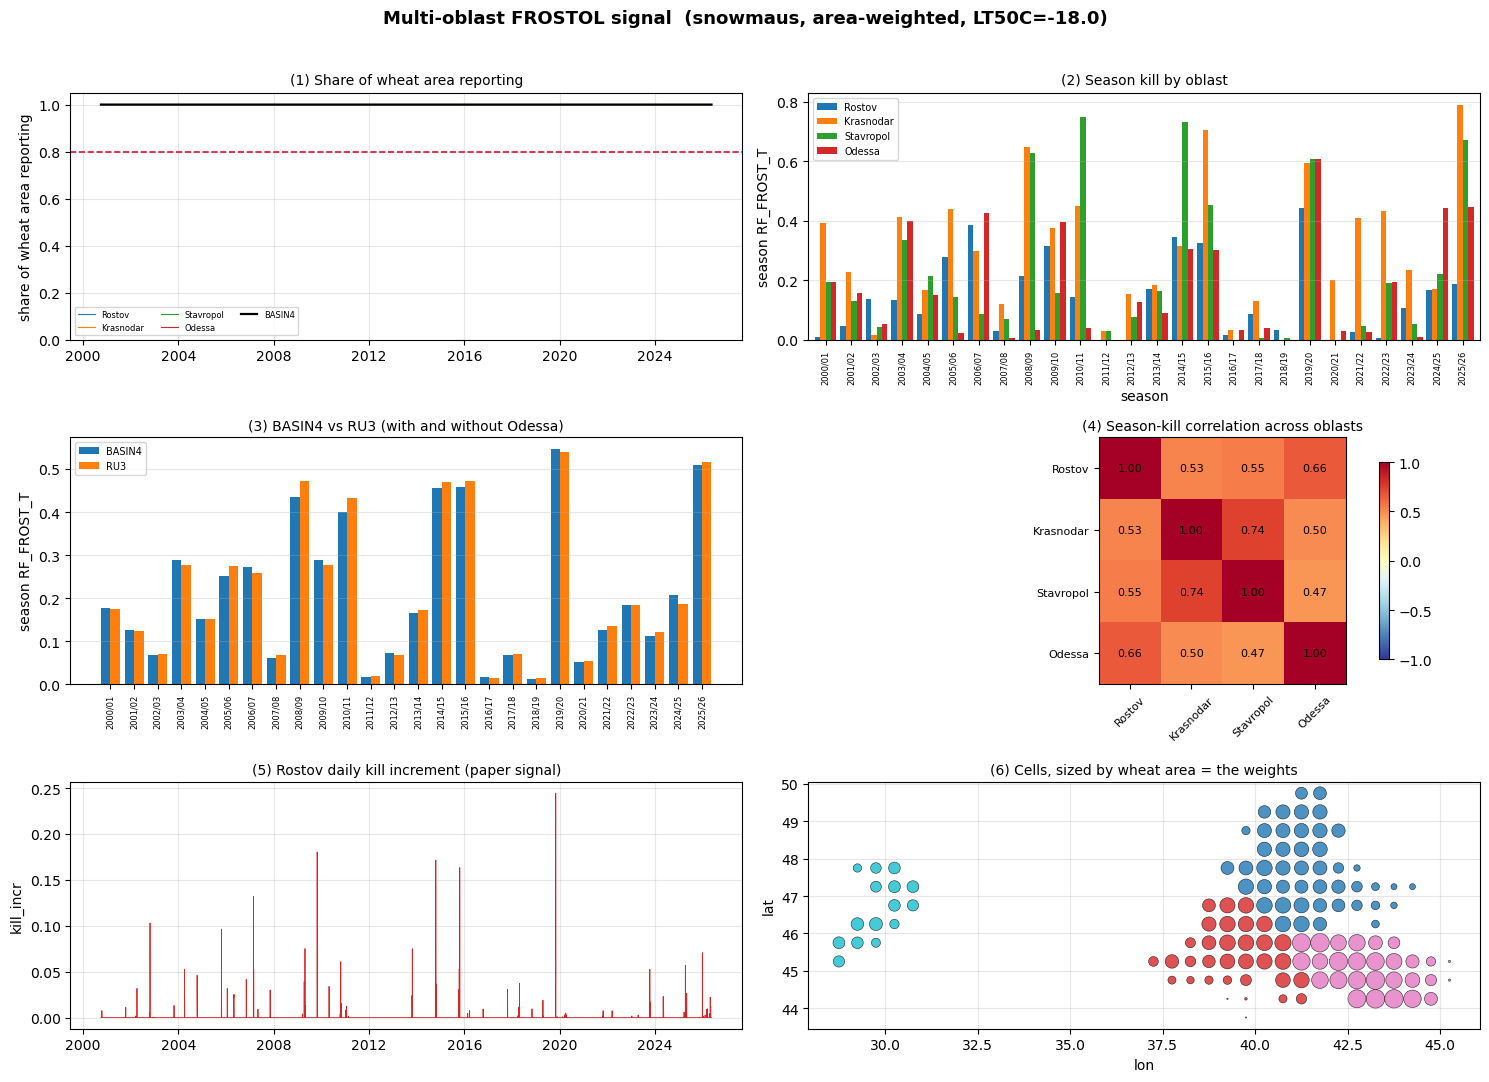


written to output/oblast_signal
   cell_status.csv
   cells_selected.csv
   frostol_basin4_daily.csv
   frostol_oblast_krasnodar_daily.csv
   frostol_oblast_odessa_daily.csv
   frostol_oblast_rostov_daily.csv
   frostol_oblast_stavropol_daily.csv
   frostol_ru3_daily.csv
   season_totals.csv


In [8]:
# ============================================================================
# 8. SEASON TABLES + DIAGNOSTIC PLOTS
# ============================================================================
def season_table(o):
    return o.groupby("season").agg(
        RF_FROST_T=("RF_FROST_T","last"),
        kill_days=("kill_incr", lambda s: int((s > 0).sum())),
        min_coverage=("wheat_coverage","min"),
        frac_days_ok=("coverage_ok","mean"))

seas = {n: season_table(o) for n, o in basins.items()}
for ob in ob_sig.columns:
    seas[ob] = season_table(obl[ob])
pd.concat({k: v for k, v in seas.items()}, names=["series"]).to_csv(OUTDIR/"season_totals.csv")

print("Rostov season totals, ranked (the paper signal):")
print(seas["Rostov"].sort_values("RF_FROST_T", ascending=False).head(12).round(3).to_string())

fig = plt.figure(figsize=(15, 11))
fig.suptitle(f"Multi-oblast FROSTOL signal  ({SNOW_SCHEME}, {WEIGHT_MODE}-weighted, "
             f"LT50C={'per-oblast' if USE_PER_OBLAST_LT50C else BASE_FROST['LT50C']})",
             fontsize=13, weight="bold")

# (1) coverage through time
ax = fig.add_subplot(3,2,1)
for ob in ob_cov.columns: ax.plot(ob_cov.index, ob_cov[ob], lw=.8, label=ob)
ax.plot(basins["BASIN4"].index, basins["BASIN4"].wheat_coverage, "k-", lw=1.6, label="BASIN4")
ax.axhline(MIN_COVERAGE, color="crimson", ls="--", lw=1.2)
ax.set_ylim(0, 1.05); ax.set_ylabel("share of wheat area reporting")
ax.set_title("(1) Share of wheat area reporting", fontsize=10)
ax.legend(fontsize=6, ncol=3); ax.grid(alpha=.3)

# (2) season totals by oblast
ax = fig.add_subplot(3,2,2)
st = pd.DataFrame({ob: seas[ob].RF_FROST_T for ob in ob_sig.columns})
st.plot(kind="bar", ax=ax, width=.85, legend=True)
ax.set_ylabel("season RF_FROST_T"); ax.tick_params(axis="x", labelsize=6, rotation=90)
ax.set_title("(2) Season kill by oblast", fontsize=10)
ax.legend(fontsize=7); ax.grid(alpha=.3, axis="y")

# (3) basin variants
ax = fig.add_subplot(3,2,3)
x = np.arange(len(seas["BASIN4"]))
for i,(n,s) in enumerate(seas.items()):
    if n in BASIN_VARIANTS:
        ax.bar(x + i*0.4, s.RF_FROST_T.reindex(seas["BASIN4"].index), width=.4, label=n)
ax.set_xticks(x + .2); ax.set_xticklabels(seas["BASIN4"].index, rotation=90, fontsize=6)
ax.set_ylabel("season RF_FROST_T")
ax.set_title("(3) BASIN4 vs RU3 (with and without Odessa)", fontsize=10)
ax.legend(fontsize=7); ax.grid(alpha=.3, axis="y")

# (4) cross-oblast correlation
ax = fig.add_subplot(3,2,4)
C = st.corr()
im = ax.imshow(C, cmap="RdYlBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(C))); ax.set_xticklabels(C.columns, rotation=45, fontsize=8)
ax.set_yticks(range(len(C))); ax.set_yticklabels(C.columns, fontsize=8)
for i in range(len(C)):
    for j in range(len(C)):
        ax.text(j, i, f"{C.iloc[i,j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("(4) Season-kill correlation across oblasts", fontsize=10)
fig.colorbar(im, ax=ax, shrink=.8)

# (5) daily kill increment of the paper signal
ax = fig.add_subplot(3,2,5)
b = obl["Rostov"]
ax.plot(b.index, b.kill_incr, lw=.6, color="tab:red")
bad = b[~b.coverage_ok]
if len(bad):
    ax.scatter(bad.index, bad.kill_incr, s=6, color="grey", label="low coverage")
    ax.legend(fontsize=7)
ax.set_ylabel("kill_incr"); ax.set_title("(5) Rostov daily kill increment (paper signal)", fontsize=10)
ax.grid(alpha=.3)

# (6) weights
ax = fig.add_subplot(3,2,6)
sc = ax.scatter(cellmeta[LONC], cellmeta[LATC], s=cellmeta[WCOL]/cellmeta[WCOL].max()*180,
                c=[list(OBLASTS).index(o) for o in cellmeta.oblast_name],
                cmap="tab10", alpha=.8, edgecolor="k", lw=.4)
ax.set_xlabel("lon"); ax.set_ylabel("lat")
ax.set_title("(6) Cells, sized by wheat area = the weights", fontsize=10)
ax.grid(alpha=.3)

plt.tight_layout(rect=[0,0,1,.965])
plt.savefig(FIGDIR / "robustness_oblast_diagnostics.png", dpi=150, bbox_inches="tight")
plt.show()
print("\nwritten to", OUTDIR.relative_to(ROOT))
for f in sorted(OUTDIR.glob("*.csv")): print("  ", f.name)

## Outputs

All files are written to `output/oblast_signal/`.

| File | Content |
|---|---|
| `frostol_oblast_rostov_daily.csv` | Daily Rostov signal used in the paper (`RF_FROST_T`, `kill_incr`, `season`, `wheat_coverage`, `coverage_ok`) |
| `frostol_oblast_krasnodar_daily.csv`, `..._stavropol_...`, `..._odessa_...` | The same for the other oblasts |
| `frostol_basin4_daily.csv`, `frostol_ru3_daily.csv` | Basin series with and without Odessa |
| `season_totals.csv` | Season kill and number of kill days per series |
| `cells_selected.csv`, `cell_status.csv` | Cell selection and run status |

The basin series are not the paper's signal. They fire on far more days than Rostov alone, which makes them closer to a winter-regime indicator than an event indicator. As in the paper, every series is read as a within-region anomaly and a year-on-year ranking rather than a literal kill percentage, because `SNOWDENSITY` and `CROWNTMPB` remain Tula-calibrated.